# Estadisticas descriptivas: Central de Deudores

Panel deudor por acreedor por mes, ago-2024 a jul-2026, **universo completo**. Personas y
empresas por separado.

Todo se lee de `panel24_wide.parquet`, que tiene un bloque de columnas por mes. Como esta en
formato ancho, cada mes son tres columnas y las diferencias entre meses consecutivos salen sin
ningun join. No se usa la muestra del 5%.

Las tablas replican lo que reportan los papers de referencia. Khwaja y Mian (2008) ponen el
foco en la distribucion de acreedores por deudor, porque de ahi sale la muestra de estimacion.
Gutierrez, Jaume y Tobal (2023) reportan acreedores por mercado, mercados por acreedor, la
fraccion de deudores con un solo prestamista y la distribucion del shock de oferta. Degryse,
Ioannidou y von Schedvin (2016) reportan la tasa a la que los deudores suman un acreedor nuevo.

Los montos son nominales. Para interpretar niveles hay que deflactarlos con `ipc.dta`; las
tablas de estructura y de riesgo no dependen de eso.

In [23]:
import os, pathlib, warnings
import duckdb, numpy as np, pandas as pd
warnings.filterwarnings("ignore")

ROOT = pathlib.Path.cwd()
while not (ROOT / "README.md").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

PROC   = ROOT / "Data" / "processed"
CENDEU = PROC / "cendeu"
CROSS  = ROOT / "Data" / "crosswalks"
OUT    = ROOT / "Code" / "output"
TAB, FIG = OUT / "tablas", OUT / "figuras"
TAB.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

WIDE    = f"'{CENDEU}/panel24_wide.parquet'"
CORTE   = f"'{CENDEU}/deudores.parquet'"
PADRON  = f"'{CENDEU}/padron.parquet'"
LENDERS = f"'{CROSS}/cendeu_lenders.csv'"

# reshape.py: bloque 00 = 2026m7, bloque i = i meses antes. ym = anio*12 + mes - 1
ANCHOR = 2026 * 12 + 7
def ym_de_bloque(i): return ANCHOR - i - 1
def ym_label(v): v = int(v); return f"{v//12}m{v%12+1}"
BLOQUES = range(24)
PRIMERO, ULTIMO = 23, 0                      # ago-2024 y jul-2026

FILTRO = {"personas": "substr(cuit,1,2) in ('20','23','24','27')",
          "empresas": "substr(cuit,1,2) in ('30','33','34')"}

def con():
    c = duckdb.connect()
    c.execute("SET memory_limit='6GB'")
    c.execute("SET preserve_insertion_order=false")
    tmp = os.path.expanduser("~/.duckdb_tmp"); os.makedirs(tmp, exist_ok=True)
    c.execute(f"SET temp_directory='{tmp}'")
    c.execute(SQL_L)
    return c

def mes(i, unidad):
    """Subconsulta con las relaciones vivas del bloque i. Sin joins ni reshape."""
    return f'''(
      select ent, cuit,
             status_{i:02d}     as status,
             amount_{i:02d}_ars as amount_ars,
             case when status_{i:02d} in (3,4,5) then 1 else 0 end as npl
      from {WIDE}
      where (status_{i:02d} > 0 or amount_{i:02d}_ars > 0) and {FILTRO[unidad]}
    )'''

def guardar(df, nombre):
    df.to_csv(TAB / f"{nombre}.csv")
    return df

print("raiz:", ROOT)

raiz: /Users/ivanurquiza/Documents/GitHub/personal/Fintech-Dynamics


## Clasificacion de acreedores

`clase` es la del regulador y sale del rango del codigo de entidad del BCRA. `tipo` es nuestra
y agrupa por modelo de negocio.

La lista de entidades con billetera propia esta escrita a mano. Hay que cotejarla contra el
registro de PSP del BCRA (`Data/raw/psp/`) por CUIT antes de usarla en una regresion.

In [24]:
BILLETERAS = (72634, 45030, 384, 143, 45072, 72638)   # MercadoLibre, Naranja Digital, Uala, Brubank, Reba, Pago Virtual del Sur

SQL_L = f'''
create or replace view L as
select ent, name, regulator_class as clase,
  case
    when regulator_class = 'financial_institution' then 'banco'
    when regulator_class = 'finance_company'       then 'cia_financiera'
    when regulator_class = 'financial_trust'       then 'fideicomiso'
    when regulator_class in ('credit_guarantee_soc','public_guarantee_fund') then 'garantia'
    when lower(name) like '%mutual%' or lower(name) like '%asociaci%' or lower(name) like '%cooperativ%'
         then 'mutual_coop'
    else 'no_bancario' end as tipo,
  case when ent in {BILLETERAS} then 1 else 0 end as billetera,
  case when regulator_class = 'financial_institution' then 1 else 0 end as es_banco
from read_csv_auto({LENDERS})
'''

c = con()
print(c.sql("select tipo, count(*) entidades, sum(billetera) con_billetera from L group by tipo order by entidades desc").df().to_string(index=False))
c.close()

          tipo  entidades  con_billetera
   no_bancario        330           2.00
   mutual_coop        100           0.00
         banco         62           2.00
      garantia         58           0.00
   fideicomiso         24           0.00
cia_financiera          3           2.00


## Tabla 1. Cobertura del panel

Conteos exactos, no estimados sobre muestra.

In [25]:
def tabla_cobertura(bloques=(PRIMERO, 11, ULTIMO)):
    filas = []
    for unidad in FILTRO:
        c = con()
        for i in bloques:
            d = c.sql(f'''
                select count(distinct cuit) deudores, count(distinct ent) acreedores,
                       count(*) relaciones, sum(amount_ars) deuda_total
                from {mes(i, unidad)} m join L using(ent)
            ''').df()
            d.insert(0, "mes", ym_label(ym_de_bloque(i))); d.insert(0, "unidad", unidad)
            filas.append(d)
        c.close()
    return pd.concat(filas).set_index(["unidad","mes"])

t1 = tabla_cobertura()
guardar(t1, "cendeu_t1_cobertura")
t1

deudores  acreedores  relaciones           deuda_total
unidad   mes                                                           
personas 2024m8  17326062         411    29523421 31,048,518,345,000.00
         2025m8  20109122         441    37397342 73,415,826,325,000.00
         2026m7  20667374         399    38826364 98,476,807,367,000.00
empresas 2024m8    225712         226      371891 31,040,032,547,000.00
         2025m8    261704         245      441376 67,337,469,822,000.00
         2026m7    285419         229      487125 92,740,916,981,000.00

## Tabla 2. Distribucion de acreedores por deudor

Esta es la tabla que decide si hay diseno within-borrower. En Gutierrez, Jaume y Tobal el 74%
de las firmas mexicanas tiene un solo banco, y por eso descartan el Khwaja-Mian.

In [26]:
def tabla_acreedores(i):
    out = []
    for unidad in FILTRO:
        c = con()
        c.execute(f'''
            create or replace table A as
            select m.cuit,
                   count(*)                                        as n_acreedores,
                   count(distinct L.tipo)                          as n_tipos,
                   sum(L.es_banco)                                 as n_bancos,
                   max(L.billetera)                                as tiene_billetera,
                   max(case when L.es_banco = 0 then 1 else 0 end) as tiene_no_banco
            from {mes(i, unidad)} m join L using(ent) group by m.cuit
        ''')
        d = c.sql('''
            select count(*) as deudores,
              avg(n_acreedores)                                                as acreedores_media,
              median(n_acreedores)                                             as acreedores_mediana,
              stddev(n_acreedores)                                             as acreedores_sd,
              100.0*avg(case when n_acreedores = 1  then 1 else 0 end)         as pct_un_acreedor,
              100.0*avg(case when n_acreedores >= 2 then 1 else 0 end)         as pct_dos_o_mas,
              100.0*avg(case when n_acreedores >= 3 then 1 else 0 end)         as pct_tres_o_mas,
              100.0*avg(case when n_bancos >= 2 then 1 else 0 end)             as pct_dos_bancos,
              100.0*avg(case when n_tipos  >= 2 then 1 else 0 end)             as pct_dos_tipos,
              100.0*avg(case when n_bancos >= 1 and tiene_no_banco = 1 then 1 else 0 end) as pct_banco_y_no_banco,
              100.0*avg(tiene_billetera)                                       as pct_con_billetera,
              100.0*avg(case when n_bancos = 0 then 1 else 0 end)              as pct_sin_banco
            from A
        ''').df()
        c.close()
        d.insert(0, "unidad", unidad); out.append(d)
    return pd.concat(out).set_index("unidad").T

t2 = pd.concat({ym_label(ym_de_bloque(PRIMERO)): tabla_acreedores(PRIMERO),
                ym_label(ym_de_bloque(ULTIMO)):  tabla_acreedores(ULTIMO)}, axis=1)
guardar(t2, "cendeu_t2_acreedores_por_deudor")
t2

2024m8                   2026m7           
unidad                    personas   empresas      personas   empresas
deudores             17,326,062.00 225,712.00 20,667,374.00 285,419.00
acreedores_media              1.70       1.65          1.88       1.71
acreedores_mediana            1.00       1.00          1.00       1.00
acreedores_sd                 1.10       1.36          1.21       1.43
pct_un_acreedor              58.26      67.42         50.50      65.24
pct_dos_o_mas                41.74      32.58         49.50      34.76
pct_tres_o_mas               16.79      14.39         22.01      15.91
pct_dos_bancos               16.09      27.87         17.98      30.02
pct_dos_tipos                29.32      11.52         38.13      12.47
pct_banco_y_no_banco         26.27      11.48         34.17      12.43
pct_con_billetera            23.66       1.63         39.06       3.41
pct_sin_banco                25.20       3.01         29.23       2.78

## Tabla 3. Deuda y riesgo por tipo de acreedor

Situacion 1 normal, 2 riesgo bajo, 3 riesgo medio, 4 riesgo alto, 5 irrecuperable. Los umbrales
de dias de atraso que corresponden a cada una estan en el texto ordenado de Clasificacion de
Deudores del BCRA. Llamamos mora a situacion 3, 4 o 5.

Va sobre el corte mensual, que es el unico que trae garantias. `provisions_ars` viene en cero
en las 41 millones de filas, asi que esa columna no se usa: hay que revisar el build o la fuente.

In [27]:
def tabla_riesgo(periodo=202607):
    c = con()
    d = c.sql(f'''
        with base as (
          select L.tipo, d.status, d.loans_ars, d.refinanced,
                 d.pref_guar_a_ars + d.pref_guar_b_ars as garantia_pref,
                 case when substr(d.cuit,1,2) in ('20','23','24','27') then 'personas' else 'empresas' end as unidad,
                 case when d.status in (3,4,5) then 1 else 0 end as mora
          from {CORTE} d join L using(ent)
          where d.period = {periodo}
            and substr(d.cuit,1,2) in ('20','23','24','27','30','33','34')
        )
        select unidad, tipo,
               count(*)                                            as relaciones,
               100.0*avg(mora)                                      as pct_mora,
               100.0*sum(case when mora=1 then loans_ars else 0 end)/nullif(sum(loans_ars),0) as pct_deuda_en_mora,
               avg(loans_ars)                                       as saldo_medio,
               median(loans_ars)                                    as saldo_mediano,
               100.0*sum(garantia_pref)/nullif(sum(loans_ars),0)     as pct_garantia_pref,
               100.0*avg(case when refinanced = 1 then 1 else 0 end) as pct_refinanciado
        from base group by unidad, tipo order by unidad, relaciones desc
    ''').df()
    c.close(); return d

t3 = tabla_riesgo()
guardar(t3.set_index(["unidad","tipo"]), "cendeu_t3_riesgo_por_tipo")
t3

,unidad,tipo,relaciones,pct_mora,pct_deuda_en_mora,saldo_medio,saldo_mediano,pct_garantia_pref,pct_refinanciado
0,empresas,banco,436043,11.67,2.71,"194,420,174.49","1,898,000.00",10.22,0.90
1,empresas,no_bancario,36747,9.77,7.12,"28,052,918.01","3,535,000.00",0.00,0.00
2,empresas,fideicomiso,9007,30.22,3.41,"136,723,741.53","11,556,000.00",48.93,0.12
3,empresas,garantia,3833,76.15,84.08,"28,611,512.65","9,024,000.00",0.00,0.00
4,empresas,mutual_coop,1175,15.91,10.16,"118,699,439.15","23,173,000.00",0.00,0.00
5,empresas,cia_financiera,320,10.94,1.17,"543,533,984.38","24,239,000.00",0.24,0.00
6,personas,banco,19610670,16.24,12.48,"3,949,387.14","1,062,000.00",23.91,1.91
7,personas,no_bancario,16032184,27.78,30.43,"795,165.49","348,000.00",0.00,0.00
8,personas,cia_financiera,1926400,39.29,22.61,"658,163.76","182,000.00",0.05,5.20
9,personas,fideicomiso,897267,77.01,19.29,"3,266,765.66","258,000.00",65.89,0.05


## Tabla 4. Estructura de mercado local

Acreedores por mercado y mercados por acreedor, que es lo que reportan Gutierrez, Jaume y Tobal
para justificar que el shock de oferta esta identificado. El mercado es el codigo postal del
deudor, que sale del padron de ARCA.

Pendiente: un crosswalk de codigo postal a departamento INDEC. Sin el, los puntos de acceso,
que vienen por departamento, solo se cruzan a nivel provincia.

In [28]:
def tabla_mercados(i=ULTIMO):
    out = []
    for unidad in FILTRO:
        c = con()
        c.execute(f'''
            create or replace table G as
            select m.cuit, m.ent, L.es_banco, pa.zip
            from {mes(i, unidad)} m join L using(ent) join {PADRON} pa using(cuit)
            where pa.zip is not null and pa.zip <> ''
        ''')
        z = c.sql('''select zip, count(distinct ent) n_acreedores,
                            count(distinct case when es_banco=1 then ent end) n_bancos,
                            count(distinct cuit) n_deudores
                     from G group by zip''').df()
        b = c.sql('''select ent, count(distinct zip) n_zips from G
                     group by ent having count(*) > 200''').df()
        c.close()
        out.append(pd.Series({
            "mercados (CP)":            len(z),
            "acreedores por CP, media": z.n_acreedores.mean(),
            "acreedores por CP, sd":    z.n_acreedores.std(),
            "bancos por CP, media":     z.n_bancos.mean(),
            "bancos por CP, mediana":   z.n_bancos.median(),
            "CP con 5 o mas bancos":    (z.n_bancos >= 5).sum(),
            "% deudores en esos CP":    100*z.loc[z.n_bancos >= 5, "n_deudores"].sum()/z.n_deudores.sum(),
            "deudores por CP, mediana": z.n_deudores.median(),
            "acreedores con cartera":   len(b),
            "CP por acreedor, media":   b.n_zips.mean(),
            "CP por acreedor, mediana": b.n_zips.median(),
        }, name=unidad))
    return pd.concat(out, axis=1)

t4 = tabla_mercados()
guardar(t4, "cendeu_t4_mercados")
t4

,personas,empresas
mercados (CP),"3,375.00","2,043.00"
"acreedores por CP, media",63.71,16.24
"acreedores por CP, sd",51.97,14.99
"bancos por CP, media",19.77,10.35
"bancos por CP, mediana",22.00,9.00
CP con 5 o mas bancos,"2,580.00","1,550.00"
% deudores en esos CP,99.99,99.45
"deudores por CP, mediana",725.00,26.00
acreedores con cartera,286.00,67.00
"CP por acreedor, media",745.05,449.19


## Tabla 5. Dinamica de las relaciones

Altas, bajas y crecimiento del saldo. El margen extensivo va primero porque el saldo de una
linea revolvente se mueve por uso del deudor y no solo por decision del acreedor. El limite,
que si es decision del acreedor, se reconstruye con `unused_ars`, pero ese campo esta solo en
el corte del mes corriente y no en el panel de 24 meses.

Como el archivo esta en formato ancho, la comparacion entre meses consecutivos sale de dos
columnas de la misma fila, sin join.

In [29]:
def tabla_dinamica(unidad):
    c = con(); filas = []
    for i in range(22, -1, -1):     # de ago-2024 en adelante, i es el mes previo a i-1
        a, b = i, i - 1             # a = mes previo, b = mes corriente
        d = c.sql(f'''
            with x as (
              select case when status_{a:02d} > 0 or amount_{a:02d}_ars > 0 then 1 else 0 end as viva_prev,
                     case when status_{b:02d} > 0 or amount_{b:02d}_ars > 0 then 1 else 0 end as viva,
                     amount_{a:02d}_ars as m_prev, amount_{b:02d}_ars as m
              from {WIDE} where {FILTRO[unidad]}
            )
            select 100.0*sum(case when viva=1 and viva_prev=0 then 1 else 0 end)
                        /nullif(sum(case when viva=1 then 1 else 0 end),0)          as pct_altas,
                   100.0*sum(case when viva=0 and viva_prev=1 then 1 else 0 end)
                        /nullif(sum(case when viva_prev=1 then 1 else 0 end),0)     as pct_bajas,
                   avg(case when viva=1 and viva_prev=1 and m>0 and m_prev>0
                            then ln(m) - ln(m_prev) end)                             as dlog_saldo_medio,
                   stddev(case when viva=1 and viva_prev=1 and m>0 and m_prev>0
                               then ln(m) - ln(m_prev) end)                          as dlog_saldo_sd
            from x
        ''').df()
        d.insert(0, "mes", ym_label(ym_de_bloque(b))); filas.append(d)
    c.close()
    return pd.concat(filas).set_index("mes")

din = {u: tabla_dinamica(u) for u in FILTRO}
t5 = pd.concat({u: d.mean() for u, d in din.items()}, axis=1)
guardar(t5, "cendeu_t5_dinamica")
guardar(din["personas"], "cendeu_t5b_dinamica_personas_mensual")
t5

ParserException: Parser Error: syntax error at or near "_ars"

LINE 4:                      case when status_-1 > 0 or amount_-1_ars > 0 then 1 else 0 end as viva,
                                                                 ^

## Tabla 6. Entrada al registro por primera vez

Cuantos deudores aparecen por primera vez dentro de la ventana y con que tipo de acreedor. Es
el margen extensivo de inclusion.

Dos advertencias. Con 24 meses no se distingue un deudor genuinamente nuevo de uno que tuvo
credito antes de ago-2024, asi que es una cota superior. Y el umbral de $25.000 para informar
deudor por deudor es nominal: con inflacion entra gente al registro sin que su situacion cambie,
asi que parte de estas altas es mecanica.

In [30]:
PRIMER_BLOQUE = "greatest(" + ", ".join(
    f"case when status_{i:02d} > 0 or amount_{i:02d}_ars > 0 then {i} else -1 end" for i in BLOQUES) + ")"

def tabla_entrantes(unidad):
    c = con()
    d = c.sql(f'''
        with w as (
          select cuit, ent, {PRIMER_BLOQUE} as primer_bloque,
                 {", ".join(f"amount_{i:02d}_ars" for i in BLOQUES)}
          from {WIDE} where {FILTRO[unidad]}
        ),
        entra as (
          select cuit, ent, primer_bloque,
                 case {" ".join(f"when primer_bloque = {i} then amount_{i:02d}_ars" for i in BLOQUES)} end as monto
          from w where primer_bloque between 0 and 22       -- 23 = ya estaba en ago-2024
        ),
        rk as (
          select e.cuit, L.tipo, L.billetera,
                 row_number() over (partition by e.cuit order by e.monto desc) as r
          from entra e join L using(ent)
        )
        select tipo, count(*) as deudores_que_entran, 100.0*avg(billetera) as pct_billetera
        from rk where r = 1 group by tipo order by deudores_que_entran desc
    ''').df()
    c.close()
    d["pct_del_total"] = 100 * d.deudores_que_entran / d.deudores_que_entran.sum()
    return d

t6 = pd.concat({u: tabla_entrantes(u).set_index("tipo") for u in FILTRO}, axis=1)
guardar(t6, "cendeu_t6_entrantes")
t6

personas                                        empresas                            
               deudores_que_entran pct_billetera pct_del_total deudores_que_entran pct_billetera pct_del_total
tipo                                                                                                          
no_bancario                8706623         51.50         50.07               17316         55.69          6.48
banco                      6366328          4.10         36.61              240466          0.21         89.96
cia_financiera             1210862         99.43          6.96                1406         96.73          0.53
fideicomiso                 863988          0.00          4.97                6110          0.00          2.29
mutual_coop                 230504          0.00          1.33                 939          0.00          0.35
garantia                      8923          0.00          0.05                1056          0.00          0.40

## Tabla 7. Los acreedores mas grandes

In [31]:
def tabla_top(unidad="personas", n=25, i=ULTIMO):
    c = con()
    d = c.sql(f'''
        select L.name as acreedor, L.tipo, L.billetera,
               count(*) as deudores, sum(m.amount_ars) as deuda,
               100.0*avg(m.npl) as pct_mora
        from {mes(i, unidad)} m join L using(ent)
        group by 1,2,3 order by deudores desc limit {n}
    ''').df()
    c.close()
    d["share_deudores"] = 100 * d.deudores / d.deudores.sum()
    return d

t7 = tabla_top("personas")
guardar(t7.set_index("acreedor"), "cendeu_t7_top_personas")
t7

,acreedor,tipo,billetera,deudores,deuda,pct_mora,share_deudores
0,MERCADOLIBRE S.R.L.,no_bancario,1,6728805,"2,947,766,052,000.00",16.98,21.00
1,TARJETA NARANJA S.A.U.,no_bancario,0,4201609,"5,145,070,965,000.00",25.01,13.11
2,BANCO DE LA NACION ARGENTINA,banco,0,2389903,"20,297,369,956,000.00",16.08,7.46
3,BANCO DE GALICIA Y BUENOS AIRES S.A.,banco,0,2333152,"10,847,542,744,000.00",22.40,7.28
4,BANCO BBVA ARGENTINA S.A.,banco,0,2074185,"6,797,953,448,000.00",21.95,6.47
5,BANCO MACRO S.A.,banco,0,1932818,"6,828,713,049,000.00",12.57,6.03
6,NARANJA DIGITAL COMPAÑÍA FINANCIERA S.A.U.,cia_financiera,1,1861278,"1,359,493,495,000.00",39.07,5.81
7,BANCO DE LA PROVINCIA DE BUENOS AIRES,banco,0,1859856,"7,160,664,339,000.00",15.50,5.80
8,BANCO SANTANDER ARGENTINA S.A.,banco,0,1777074,"8,580,006,536,000.00",13.00,5.55
9,INDUSTRIAL AND COMMERCIAL BANK OF CHINA (ARGEN...,banco,0,613602,"2,621,581,497,000.00",13.02,1.92


## Tabla 8. Demografia de los deudores

Del padron de ARCA. Solo tiene sentido para personas.

In [32]:
def tabla_demografia(i=ULTIMO):
    c = con()
    d = c.sql(f'''
        with base as (
          select distinct m.cuit, pa.birth_date, pa.sex, pa.province, pa.zip
          from {mes(i, "personas")} m join {PADRON} pa using(cuit)
        )
        select count(*) as deudores,
          100.0*avg(case when sex = 'F' then 1 else 0 end) as pct_mujeres,
          avg(2026 - cast(substr(birth_date,1,4) as int))    as edad_media,
          median(2026 - cast(substr(birth_date,1,4) as int)) as edad_mediana,
          100.0*avg(case when 2026 - cast(substr(birth_date,1,4) as int) < 30 then 1 else 0 end) as pct_menos_30,
          100.0*avg(case when 2026 - cast(substr(birth_date,1,4) as int) > 60 then 1 else 0 end) as pct_mas_60,
          count(distinct province) as provincias, count(distinct zip) as codigos_postales
        from base where birth_date is not null and birth_date <> ''
    ''').df()
    c.close(); return d.T.rename(columns={0: "personas"})

t8 = tabla_demografia()
guardar(t8, "cendeu_t8_demografia")
t8

,personas
deudores,"20,645,898.00"
pct_mujeres,51.64
edad_media,46.88
edad_mediana,45.00
pct_menos_30,15.57
pct_mas_60,22.34
provincias,24.00
codigos_postales,"3,376.00"


## Tabla 9. Deudores y puntos de acceso, por provincia

Cruza la Central de Deudores con `pda_depto.parquet`, que construye
`Code/build/build_puntos_acceso.py`. Es el insumo de la pregunta de inclusion: donde no hay
sucursal, quien presta.

Dos limitaciones. Va a nivel provincia porque los puntos de acceso vienen por departamento
INDEC y el padron da codigo postal; el crosswalk entre los dos es la pieza que falta para bajar
a mercado local. Y el panel de puntos de acceso termina en dic-2025, siete meses antes que la
Central de Deudores.

In [33]:
PDA  = PROC / "pda_depto.parquet"
XPRO = CROSS / "provincias_arca_indec.csv"

if PDA.exists() and XPRO.exists():
    c = con()
    deu = c.sql(f'''
        select pa.province as cod_prov_arca,
               count(distinct m.cuit)                              as deudores,
               100.0*avg(case when L.es_banco=0 then 1 else 0 end)  as pct_rel_no_bancarias,
               100.0*avg(L.billetera)                               as pct_rel_billetera,
               100.0*avg(m.npl)                                     as pct_mora
        from {mes(ULTIMO, "personas")} m join L using(ent) join {PADRON} pa using(cuit)
        group by 1
    ''').df()
    ym_pda = c.sql(f"select max(ym) from '{PDA}'").fetchone()[0]
    pda = c.sql(f'''
        select cod_prov, sum(sucursales) sucursales, sum(atm) atm, sum(pda_total) pda_total
        from '{PDA}' where ym = {ym_pda} group by 1
    ''').df()
    c.close()
    print(f"puntos de acceso: ultimo mes ym={ym_pda} en meses de Stata (708 = 2019m1, 791 = 2025m12)")

    x = pd.read_csv(XPRO, dtype=str)
    deu["cod_prov_arca"] = deu.cod_prov_arca.astype(int).astype(str).str.zfill(2)
    m = (deu.merge(x, on="cod_prov_arca", how="left")
            .merge(pda, left_on="cod_prov_indec", right_on="cod_prov", how="left"))
    m["deudores_por_sucursal"] = m.deudores / m.sucursales
    t9 = m[["provincia","deudores","sucursales","atm","deudores_por_sucursal",
            "pct_rel_no_bancarias","pct_rel_billetera","pct_mora"]].sort_values("deudores", ascending=False)
    guardar(t9.set_index("provincia"), "cendeu_t9_pda_provincia")
else:
    t9 = None
    print("falta", PDA, "o", XPRO, "- correr Code/build/build_puntos_acceso.py")
t9

puntos de acceso: ultimo mes ym=791 en meses de Stata (708 = 2019m1, 791 = 2025m12)


,provincia,deudores,sucursales,atm,deudores_por_sucursal,pct_rel_no_bancarias,pct_rel_billetera,pct_mora
15,BUENOS AIRES,7584269,"1,452.00","6,115.00","5,223.33",45.87,24.31,25.59
3,CABA,2050336,693.00,"2,341.00","2,958.64",31.92,18.59,15.42
12,CORDOBA,1820532,469.00,"1,968.00","3,881.73",53.37,21.60,22.38
13,SANTA FE,1609951,500.00,"1,822.00","3,219.90",46.86,21.18,20.99
18,MENDOZA,881129,186.00,740.00,"4,737.25",55.78,24.84,25.65
7,TUCUMAN,711853,101.00,624.00,"7,048.05",57.69,18.65,27.91
8,ENTRE RIOS,581723,137.00,650.00,"4,246.15",52.11,23.03,20.02
10,SALTA,552020,80.00,555.00,"6,900.25",56.65,23.16,26.98
19,MISIONES,506664,70.00,492.00,"7,238.06",50.69,23.45,25.39
6,CHACO,490143,102.00,472.00,"4,805.32",58.72,23.13,27.58


## Figura 1. Evolucion de la estructura del deudor

Fraccion de deudores con dos o mas acreedores, con dos o mas tipos, con banco y no banco a la
vez, y con dos o mas bancos. Es la muestra de estimacion del diseno within-borrower a lo largo
del tiempo.

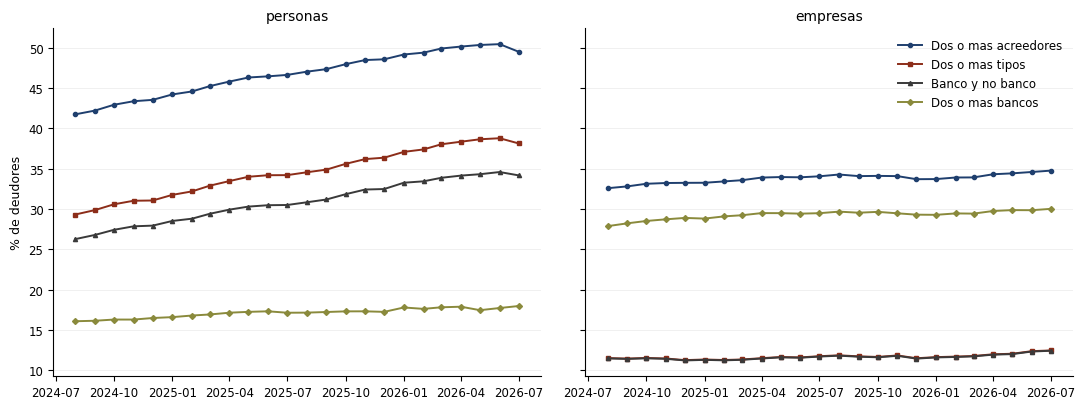

In [34]:
import matplotlib
import matplotlib.pyplot as plt

def serie_estructura(unidad):
    c = con(); filas = []
    for i in BLOQUES:
        d = c.sql(f'''
            with a as (
              select m.cuit, count(*) n, count(distinct L.tipo) ntipo,
                     sum(L.es_banco) nb, max(case when L.es_banco=0 then 1 else 0 end) nnb
              from {mes(i, unidad)} m join L using(ent) group by m.cuit
            )
            select 100.0*avg(case when n>=2 then 1 else 0 end)            as dos_o_mas,
                   100.0*avg(case when ntipo>=2 then 1 else 0 end)        as dos_tipos,
                   100.0*avg(case when nb>=1 and nnb=1 then 1 else 0 end) as banco_y_no_banco,
                   100.0*avg(case when nb>=2 then 1 else 0 end)           as dos_bancos
            from a
        ''').df()
        d.insert(0, "ym", ym_de_bloque(i)); filas.append(d)
    c.close()
    return pd.concat(filas).sort_values("ym")

ESTILO = {"dos_o_mas": ("Dos o mas acreedores", "#1f3f6e", "o"),
          "dos_tipos": ("Dos o mas tipos", "#8c2d19", "s"),
          "banco_y_no_banco": ("Banco y no banco", "#3a3a3a", "^"),
          "dos_bancos": ("Dos o mas bancos", "#8a8a3c", "D")}

series = {u: serie_estructura(u) for u in FILTRO}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, (unidad, s) in zip(axes, series.items()):
    x = [pd.Period(year=int(v)//12, month=int(v)%12+1, freq="M").to_timestamp() for v in s.ym]
    for col, (lab, cl, mk) in ESTILO.items():
        ax.plot(x, s[col], color=cl, marker=mk, ms=3, lw=1.4, label=lab)
    ax.set_title(unidad, size=10)
    ax.tick_params(labelsize=8.5); ax.grid(axis="y", alpha=.22, lw=.6)
    for sp in ["top","right"]: ax.spines[sp].set_visible(False)
axes[0].set_ylabel("% de deudores", size=9)
axes[1].legend(fontsize=8.5, frameon=False)
fig.tight_layout(); fig.savefig(FIG / "cendeu_estructura_deudor.pdf")
guardar(pd.concat({u: s.set_index("ym") for u, s in series.items()}, axis=1), "cendeu_f1_estructura")
plt.show()

## Figura 2. Distribucion del shock de oferta

Estimacion a la Greenstone, Mas y Nguyen, como en Gutierrez, Jaume y Tobal: una regresion por
trimestre del cambio del log del credito del banco en el mercado local sobre efectos fijos de
mercado y de banco. El efecto fijo de banco es el shock.

Tres advertencias. En frecuencia mensual se pierden demasiadas celdas al tomar log-diferencias,
que es la misma razon por la que ellos van a frecuencia anual, asi que va trimestral. Los
trimestres incompletos se descartan. Y falta el leave-one-out: el mercado al que despues se le
asigna el shock participa de su estimacion. Con cientos de mercados por banco es de segundo
orden, pero conviene implementarlo antes de la version final, porque es el defecto que ese paper
tiene y se corrige gratis.

shocks: 294   bancos: 50   trimestres: 6
             count  mean  std   min   10%   25%   50%  75%  90%  max
gamma_bruto 294.00  0.14 0.17 -0.33 -0.02  0.05  0.12 0.22 0.28 1.24
gamma       294.00  0.00 0.16 -0.48 -0.14 -0.07 -0.01 0.05 0.14 1.11

dispersion entre bancos dentro de cada trimestre, comparable con el 0,16 de Tobal:
       bancos   sd
trim              
24300      49 0.17
24303      49 0.13
24306      49 0.13
24309      49 0.20
24312      49 0.20
24315      49 0.11


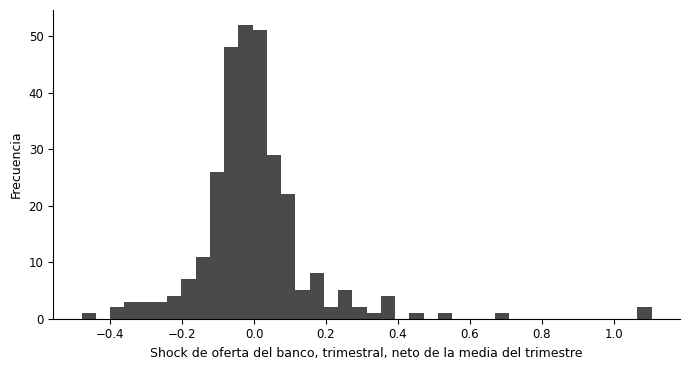

In [35]:
def credito_banco_cp(unidad="personas"):
    """Saldo por banco, codigo postal y mes. Una pasada por mes."""
    c = con(); filas = []
    for i in BLOQUES:
        d = c.sql(f'''
            select m.ent, pa.zip, sum(m.amount_ars) as saldo
            from {mes(i, unidad)} m join L using(ent) join {PADRON} pa using(cuit)
            where L.es_banco = 1 and pa.zip is not null and pa.zip <> ''
            group by 1, 2
        ''').df()
        d["ym"] = ym_de_bloque(i); filas.append(d)
    c.close()
    return pd.concat(filas)

def shock_oferta(g_raw, min_obs=30):
    g_raw = g_raw.copy()
    g_raw["trim"] = g_raw.ym - (g_raw.ym % 3)
    q = (g_raw.groupby(["ent","zip","trim"])
               .agg(saldo=("saldo","sum"), n=("ym","size")).reset_index())
    q = q[q.n == 3]                                   # trimestres completos
    q = q.sort_values(["ent","zip","trim"])
    q["dlog"] = np.log(q.saldo) - np.log(q.groupby(["ent","zip"]).saldo.shift(1))
    d = q.dropna(subset=["dlog"]).query("abs(dlog) < 3")

    res = []
    for trim, sub in d.groupby("trim"):
        sub = sub[sub.groupby("ent").ent.transform("size") >= min_obs]
        if sub.ent.nunique() < 5: continue
        y = sub.dlog.values.astype(float).copy()
        for _ in range(60):
            for k in ["zip", "ent"]:
                y = y - pd.Series(y).groupby(sub[k].values).transform("mean").values
        gamma = (sub.dlog - y).groupby(sub.ent).mean()
        # el nivel de cada trimestre es inflacion mas ciclo, comun a todos los bancos.
        # gamma_bruto lo conserva, como en Gutierrez-Jaume-Tobal, cuyo shock tampoco esta
        # centrado en cero. gamma lo saca, y es la variacion que identifica.
        res.append(pd.DataFrame({"trim": trim, "ent": gamma.index,
                                 "gamma_bruto": gamma.values,
                                 "gamma": gamma.values - gamma.mean()}))
    return pd.concat(res)

bcp = credito_banco_cp("personas")
g = shock_oferta(bcp)
print(f"shocks: {len(g)}   bancos: {g.ent.nunique()}   trimestres: {g.trim.nunique()}")
print(g[["gamma_bruto","gamma"]].describe(percentiles=[.1,.25,.5,.75,.9]).T)
print("\ndispersion entre bancos dentro de cada trimestre, comparable con el 0,16 de Tobal:")
print(g.groupby("trim").gamma.agg(bancos="count", sd="std").round(3))
g.to_csv(TAB / "cendeu_shock_oferta.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(g.gamma, bins=40, color="#4a4a4a")
ax.set_xlabel("Shock de oferta del banco, trimestral, neto de la media del trimestre", size=9)
ax.set_ylabel("Frecuencia", size=9); ax.tick_params(labelsize=8.5)
for sp in ["top","right"]: ax.spines[sp].set_visible(False)
fig.tight_layout(); fig.savefig(FIG / "cendeu_shock_oferta.pdf")
plt.show()

## Validacion del shock contra el balance del banco

Es la Tabla 4 de Gutierrez, Jaume y Tobal: si el shock estimado no correlaciona con nada del
balance, no es oferta. Ellos encuentran que sube fuerte con la tasa pasiva del banco. Nosotros
tenemos el balance mensual desde 2018, que es mejor dato que el que ellos usaron.

In [36]:
BAL = PROC / "balances_bancos.dta"

if BAL.exists():
    b = pd.read_stata(BAL)
    b["ym"] = b["ym"].dt.year * 12 + b["ym"].dt.month - 1
    b["trim"] = b.ym - (b.ym % 3)
    b["liquidez"]   = b.efectivo / b.activo
    b["capital"]    = b.pn / b.activo
    b["dep_activo"] = b.depositos / b.activo
    b["pf_dep"]     = b.dep_pfijo / b.depositos
    agg = b.groupby(["ent","trim"])[["liquidez","capital","dep_activo","pf_dep","activo"]].mean().reset_index()
    agg["log_activo"] = np.log(agg.activo)

    m = g.merge(agg, on=["ent","trim"], how="inner")
    X = ["log_activo","liquidez","capital","dep_activo","pf_dep"]
    print(f"observaciones banco-trimestre con las dos patas: {len(m)}")
    val = m[["gamma"] + X].corr().loc["gamma", X].to_frame("corr con el shock")
    guardar(val, "cendeu_validacion_shock")
    display(val)
else:
    print("falta", BAL, "- correr Code/build/build_dta.do")

AttributeError: 'DataFrame' object has no attribute 'dep_pfijo'

## Exportar a LaTeX

In [ ]:
for f in sorted(TAB.glob("cendeu_*.csv")):
    pd.read_csv(f, index_col=0).to_latex(f.with_suffix(".tex"), float_format="%.2f", escape=True)
print("\n".join(p.name for p in sorted(TAB.glob("cendeu_*"))))